In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import medfilt, savgol_filter

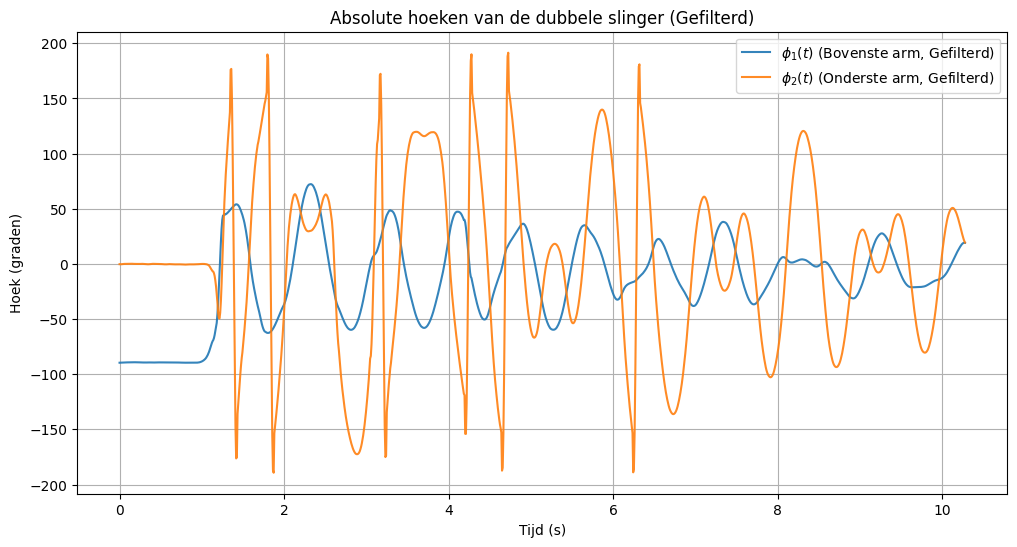

In [ ]:
CSV_FILE = 'meting_90_1_234_data.csv'  # Pas dit aan naar jouw bestandsnaam

# Coördinaten van het vaste ophangpunt (pivot) in pixels
X0 = 924.1 #528.4 # 
Y0 = 319.1  #255.1 #

# Kalibratie (Stap 13): Hoeveel pixels is 1 meter in jouw video?
# (Bijv: als een stang van 30cm in de video 150 pixels lang is -> 150 / 0.3 = 500 px/m)
PIXELS_PER_METER = 62 / 0.05 #(149/3) / 0.05  #
FPS = 118.5
DT = 1.0 / FPS

df = pd.read_csv(CSV_FILE)
df = df.dropna()

df = df[df['red_x'] > 200]

#  pixelcoördinaten inladen
X1_raw, Y1_raw = df['red_x'].values, df['red_y'].values
X2_raw, Y2_raw = df['green_x'].values, df['green_y'].values


# uitschieters  verwijderen die niet goed getracked zijn

# window_size bepaalt over hoeveel frames hij kijkt (moet oneven zijn). 

window_size = 7 

X1 = medfilt(X1_raw, kernel_size=window_size)
Y1 = medfilt(Y1_raw, kernel_size=window_size)
X2 = medfilt(X2_raw, kernel_size=window_size)
Y2 = medfilt(Y2_raw, kernel_size=window_size)


# hoeken berekenen
phi1 = np.arctan2(X1 - X0, Y1 - Y0)
phi2 = np.arctan2(X2 - X1, Y2 - Y1)


# Filter 2: Vloeiend maken (Savitzky-Golay)
# maakt de curve glad voor latere berekeningen.
sg_window = 11
poly_order = 3

phi1_smooth = savgol_filter(phi1, sg_window, poly_order)
phi2_smooth = savgol_filter(phi2, sg_window, poly_order)

phi1_graden = np.degrees(phi1_smooth)
phi2_graden = np.degrees(phi2_smooth)

# plotten van de hoeken over tijd

tijd = np.arange(len(phi1_graden)) * DT

plt.figure(figsize=(12, 6))
plt.plot(tijd, phi1_graden, label=r'$\phi_1(t)$ (Bovenste arm, Gefilterd)', alpha=0.9, linewidth=1.5)
plt.plot(tijd, phi2_graden, label=r'$\phi_2(t)$ (Onderste arm, Gefilterd)', alpha=0.9, linewidth=1.5)

plt.title('Absolute hoeken van de dubbele slinger (Gefilterd)')
plt.xlabel('Tijd (s)')
plt.ylabel('Hoek (graden)')
plt.legend()
plt.grid(True)

plt.show()

Berekende lengte arm 1: 0.292 m
Berekende lengte arm 2: 0.218 m


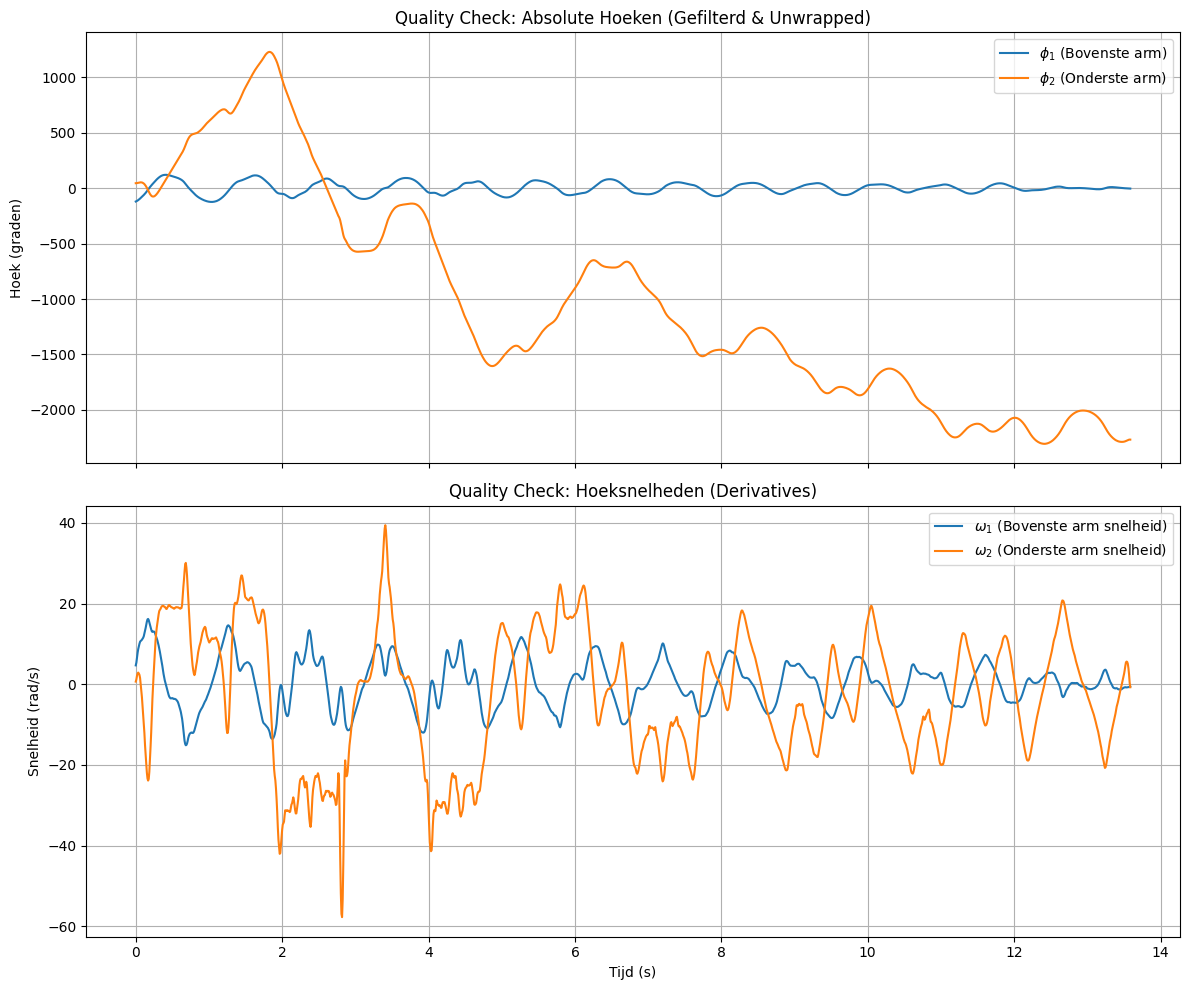

In [ ]:
# massa
M1 = 0.6809  # [kg]
M2 = 0.2093  # [kg]

# data inladen
df = pd.read_csv(CSV_FILE)
df = df.dropna()
df = df[df['red_x'] > 200]

X1_raw, Y1_raw = df['red_x'].values, df['red_y'].values
X2_raw, Y2_raw = df['green_x'].values, df['green_y'].values

window_size = 7 
X1 = medfilt(X1_raw, kernel_size=window_size)
Y1 = medfilt(Y1_raw, kernel_size=window_size)
X2 = medfilt(X2_raw, kernel_size=window_size)
Y2 = medfilt(Y2_raw, kernel_size=window_size)

# lengtes 
L1 = np.mean(np.sqrt((X1 - X0)**2 + (Y1 - Y0)**2)) / PIXELS_PER_METER
L2 = np.mean(np.sqrt((X2 - X1)**2 + (Y2 - Y1)**2)) / PIXELS_PER_METER
print(f"Berekende lengte arm 1: {L1:.3f} m")
print(f"Berekende lengte arm 2: {L2:.3f} m")

# berekenen hoeken van de armen
phi1 = np.arctan2(X1 - X0, Y1 - Y0)
phi2 = np.arctan2(X2 - X1, Y2 - Y1)

phi1 = np.unwrap(phi1) # unwrap voor voorkomen fouten
phi2 = np.unwrap(phi2) # unwrap voor voorkomen fouten

# 3. Savitzky-Golay filter toepassen op de ononderbroken hoeken
sg_window = 11
poly_order = 3
phi1_smooth = savgol_filter(phi1, sg_window, poly_order)
phi2_smooth = savgol_filter(phi2, sg_window, poly_order)

# hoeksnelheden berekenen door te differentiëren

omega1 = np.gradient(phi1_smooth, DT)
omega2 = np.gradient(phi2_smooth, DT)

# Gegeneraliseerde momenta (p1, p2) berekenen met punt-massa benadering
delta_phi = phi1_smooth - phi2_smooth
p1 = (M1 + M2) * (L1**2) * omega1 + M2 * L1 * L2 * omega2 * np.cos(delta_phi)
p2 = M2 * (L2**2) * omega2 + M2 * L1 * L2 * omega1 * np.cos(delta_phi)


# nieuw file creeeren

tijd = np.arange(len(phi1_smooth)) * DT

# # Creëer een DataFrame met de canonical coordinates
# export_df = pd.DataFrame({
#     'time_s': tijd,
#     'phi1_rad': phi1_smooth,
#     'phi2_rad': phi2_smooth,
#     'omega1_rad_s': omega1,
#     'omega2_rad_s': omega2,
#     'p1': p1,
#     'p2': p2
# })

# # Exporteer naar een nieuwe CSV file
# export_filename = 'canonical_coordinates_180_2_repaired.csv'
# export_df.to_csv(export_filename, index=False)
# print(f"Data succesvol geëxporteerd naar {export_filename}")

# ==============================================================================
# QUALITY POINTER: Plot hoeken en snelheden
# ==============================================================================
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10), sharex=True)

# Plot 1: Hoeken (Voor de overzichtelijkheid omgezet naar graden in de plot)
ax1.plot(tijd, np.degrees(phi1_smooth), label=r'$\phi_1$ (Bovenste arm)')
ax1.plot(tijd, np.degrees(phi2_smooth), label=r'$\phi_2$ (Onderste arm)')
ax1.set_title('Quality Check: Absolute Hoeken (Gefilterd & Unwrapped)')
ax1.set_ylabel('Hoek (graden)')
ax1.legend()
ax1.grid(True)

# Plot 2: Hoeksnelheden (Derivatives)
ax2.plot(tijd, omega1, label=r'$\omega_1$ (Bovenste arm snelheid)')
ax2.plot(tijd, omega2, label=r'$\omega_2$ (Onderste arm snelheid)')
ax2.set_title('Quality Check: Hoeksnelheden (Derivatives)')
ax2.set_xlabel('Tijd (s)')
ax2.set_ylabel('Snelheid (rad/s)')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

342 280
976 976 976

--- Initiële Condities (bij tau = 0) ---
Meting A:
  Hoek 1 (phi1) : 1.3402 rad
  Hoek 2 (phi2) : 13.1736 rad
  Impuls 1 (p1) : -0.0072 kg*m^2/s
  Impuls 2 (p2) : -0.0178 kg*m^2/s

Meting B:
  Hoek 1 (phi1) : 1.2776 rad
  Hoek 2 (phi2) : 7.2040 rad
  Impuls 1 (p1) : -0.0859 kg*m^2/s
  Impuls 2 (p2) : -0.0627 kg*m^2/s
----------------------------------------

--- ANALYSE RESULTATEN ---
Initiële fase-afstand delta(0) : 0.5097
Fit interval tau               : [0.55, 0.75] s
Divergentiesnelheid (Lambda)   : 11.428



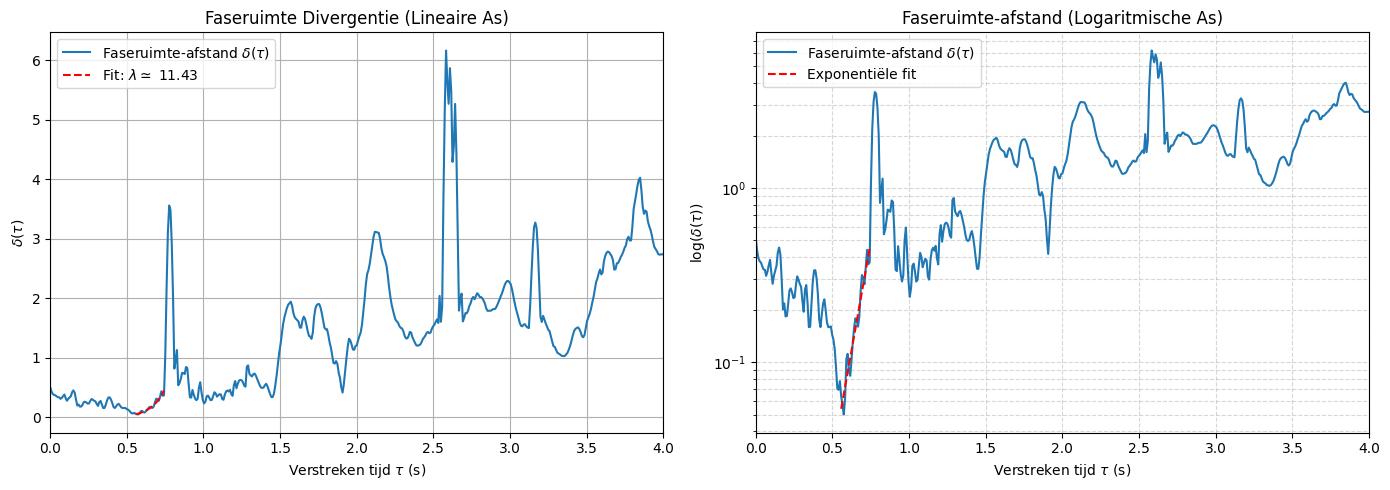

In [ ]:
# analyseren data

FILE_A = 'canonical_coordinates_90_2.csv'
FILE_B = 'canonical_coordinates_90_3.csv'

PEAK_SEARCH_MIN = 200 
PEAK_SEARCH_MAX = 400 


FIT_TAU_MIN = 0.55
FIT_TAU_MAX = 0.75


# data verwerken

df_A = pd.read_csv(FILE_A)
df_B = pd.read_csv(FILE_B)

# Normalisatieschalen bepalen (o.b.v. dataset A als referentie)
norm_phi1 = np.std(df_A['phi1_rad'])
norm_phi2 = np.std(df_A['phi2_rad'])
norm_p1   = np.std(df_A['p1'])
norm_p2   = np.std(df_A['p2'])

# Synchroniseren op de eerste piek (verwijderen van opstart-ruis)
crop_idx_A = df_A['phi1_rad'].iloc[PEAK_SEARCH_MIN:PEAK_SEARCH_MAX].idxmax()
crop_idx_B = df_B['phi1_rad'].iloc[PEAK_SEARCH_MIN:PEAK_SEARCH_MAX].idxmax()
print(crop_idx_A, crop_idx_B)

df_A = df_A.iloc[crop_idx_A:].copy()
df_B = df_B.iloc[crop_idx_B:].copy()

# Tijd resetten naar tau = 0
df_A['tau'] = df_A['time_s'] - df_A['time_s'].iloc[0]
df_B['tau'] = df_B['time_s'] - df_B['time_s'].iloc[0]

# Gelijk maken in lengte voor 1-op-1 vergelijking
min_len = min(len(df_A), len(df_B))
df_A = df_A.iloc[:min_len].reset_index(drop=True)
df_B = df_B.iloc[:min_len].reset_index(drop=True)
tau = df_A['tau'].values
print(min_len, len(df_A), len(df_B))

print("\n--- Initiële Condities (bij tau = 0) ---")
print("Meting A:")
print(f"  Hoek 1 (phi1) : {df_A['phi1_rad'].iloc[0]:.4f} rad")
print(f"  Hoek 2 (phi2) : {df_A['phi2_rad'].iloc[0]:.4f} rad")
print(f"  Impuls 1 (p1) : {df_A['p1'].iloc[0]:.4f} kg*m^2/s")
print(f"  Impuls 2 (p2) : {df_A['p2'].iloc[0]:.4f} kg*m^2/s")

print("\nMeting B:")
print(f"  Hoek 1 (phi1) : {df_B['phi1_rad'].iloc[0]:.4f} rad")
print(f"  Hoek 2 (phi2) : {df_B['phi2_rad'].iloc[0]:.4f} rad")
print(f"  Impuls 1 (p1) : {df_B['p1'].iloc[0]:.4f} kg*m^2/s")
print(f"  Impuls 2 (p2) : {df_B['p2'].iloc[0]:.4f} kg*m^2/s")
print("----------------------------------------\n")

# ==============================================================================
# 3. VERSCHIL BEREKENEN MET HOEK-WRAPPING (CRUCIAAL)
# ==============================================================================
# In plaats van directe aftreksom, dwingen we het verschil tussen -pi en +pi
delta_theta1 = (df_A['phi1_rad'] - df_B['phi1_rad'] + np.pi) % (2 * np.pi) - np.pi
delta_theta2 = (df_A['phi2_rad'] - df_B['phi2_rad'] + np.pi) % (2 * np.pi) - np.pi

# Impulsen roteren niet over 360 graden, dus die kunnen normaal afgetrokken worden
delta_p1 = df_A['p1'] - df_B['p1']
delta_p2 = df_A['p2'] - df_B['p2']

# Dimensieloze Euclidische faseruimte-afstand
delta_tau = np.sqrt(
    (delta_theta1**2 / norm_phi1**2) + 
    (delta_p1**2     / norm_p1**2) + 
    (delta_theta2**2 / norm_phi2**2) + 
    (delta_p2**2     / norm_p2**2)
)

ln_delta = np.log(delta_tau + 1e-12) # 1e-12 voorkomt log(0) error


# =fit for Lyapunov exponent

mask = (tau >= FIT_TAU_MIN) & (tau <= FIT_TAU_MAX)
fit_coeffs = np.polyfit(tau[mask], ln_delta[mask], 1)
lambda_exp = fit_coeffs[0]
b = fit_coeffs[1]
fit_line = np.exp(lambda_exp * tau[mask] + b)

# resultaten

print(f" resultaten ")
print(f"Initiële fase-afstand delta(0) : {delta_tau[0]:.4f}")
print(f"Fit interval tau               : [{FIT_TAU_MIN}, {FIT_TAU_MAX}] s")
print(f"Divergentiesnelheid (Lambda)   : {lambda_exp:.3f}\n")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# data plotten
ax1.plot(tau, delta_tau, label=r'Faseruimte-afstand $\delta(\tau)$', color='#1f77b4')
ax1.plot(tau[mask], fit_line, color='red', linewidth=1.5, linestyle='--', label=rf'Fit: $\lambda \simeq$ {lambda_exp:.2f}')
ax1.set_title('Faseruimte Divergentie (Lineaire As)')
ax1.set_xlabel(r'Verstreken tijd $\tau$ (s)')
ax1.set_ylabel(r'$\delta(\tau)$')
ax1.set_xlim(0, 4) 
ax1.legend()
ax1.grid(True)

# Plot met logaritmische as
ax2.plot(tau, delta_tau, label=r'Faseruimte-afstand $\delta(\tau)$', color='#1f77b4')
ax2.plot(tau[mask], fit_line, color='red', linewidth=1.5, linestyle='--', label=rf'Exponentiële fit')
ax2.set_yscale('log')
ax2.set_title('Faseruimte-afstand (Logaritmische As)')
ax2.set_xlabel(r'Verstreken tijd $\tau$ (s)')
ax2.set_ylabel(r'$\log(\delta(\tau))$')
ax2.set_xlim(0, 4)
ax2.legend()
ax2.grid(True, which="both", ls="--", alpha=0.5)

plt.tight_layout()
plt.show()

<>:33: SyntaxWarning: invalid escape sequence '\l'
<>:35: SyntaxWarning: invalid escape sequence '\l'
<>:33: SyntaxWarning: invalid escape sequence '\l'
<>:35: SyntaxWarning: invalid escape sequence '\l'
C:\Users\Vera Reeringh\AppData\Local\Temp\ipykernel_31688\2025200104.py:33: SyntaxWarning: invalid escape sequence '\l'
  plt.title('Lyapunov-exponent ($\lambda$) tegen beginhoek', fontsize=14)
C:\Users\Vera Reeringh\AppData\Local\Temp\ipykernel_31688\2025200104.py:35: SyntaxWarning: invalid escape sequence '\l'
  plt.ylabel('Benaderde $\lambda$', fontsize=12)


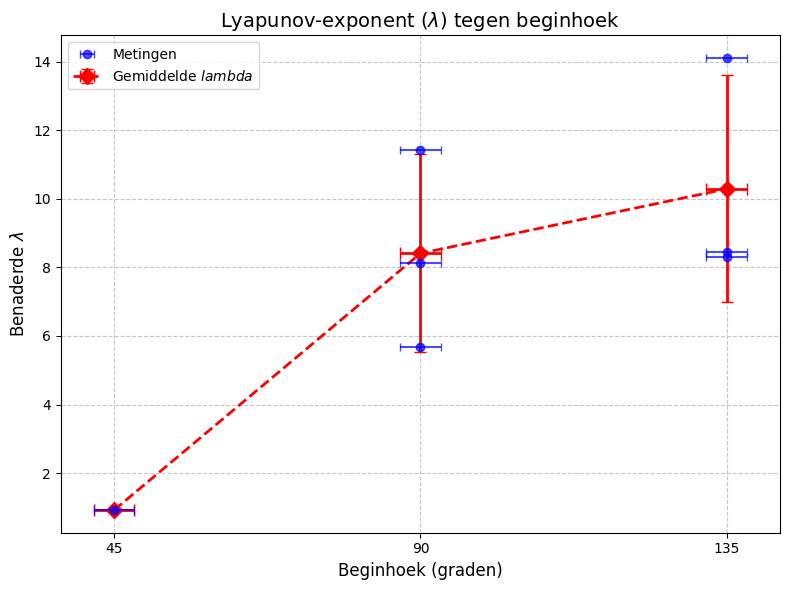

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Data
fit_lapda = np.array([0.92, 5.67, 8.13, 11.43, 14.11, 8.46, 8.31])
hoek = np.array([45, 90, 90, 90, 135, 135, 135])

plt.figure(figsize=(8, 6))

# Onzekerheid voor de hoek vanuit de tabel
x_err = 3 # onzekerheid rgraden

# Plot de individuele datapunten met errorbars
plt.errorbar(hoek, fit_lapda, xerr=x_err, fmt='o', color='blue', alpha=0.7, 
             label='Metingen', capsize=3, zorder=5)

# gemiddelden en standaarddeviaties per hoek
unique_hoeken = sorted(list(set(hoek)))
means = []
stds = []

for h in unique_hoeken:
    subset = fit_lapda[hoek == h]
    means.append(np.mean(subset))
    # Als er maar 1 meting is (bijv. 45 graden), zetten we de y-spreiding op 0 (of een kleine schatting)
    stds.append(np.std(subset, ddof=1) if len(subset) > 1 else 0.0)

# errorbars toevoegen
plt.errorbar(unique_hoeken, means, xerr=x_err, yerr=stds, fmt='--D', color='red', 
             markersize=8, linewidth=2, label='Gemiddelde $\lambda$', capsize=4, zorder=4)

# Grafiek Lyapunov exponent
plt.title('Lyapunov-exponent ($\lambda$) tegen beginhoek', fontsize=14)
plt.xlabel('Beginhoek (graden)', fontsize=12)
plt.ylabel('Benaderde $\lambda$', fontsize=12)
plt.xticks(unique_hoeken)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(fontsize=10)

plt.tight_layout()
plt.show()

In [ ]:
# het berekenen gemiddelden en onzekerheden per hoek

unique_hoeken = sorted(list(set(hoek)))

print("Overzicht van gemiddelde Lyapunov-exponent (lambda) en onzekerheid per hoek:")
print("-" * 75)
print(f"{'Hoek (°)':<10} | {'Aantal metingen':<16} | {'Gemiddelde lambda':<20} | {'Onzekerheid (SEM)':<18}")
print("-" * 75)

for h in unique_hoeken:
    subset = fit_lapda[hoek == h]
    gemiddelde = np.mean(subset)
    n = len(subset)
    
    if n > 1:
        # Standaarddeviatie gedeeld door wortel(n) geeft de standaardfout (SEM)
        stdev = np.std(subset, ddof=1)
        sem = stdev / np.sqrt(n)
 
        
    print(f"{h:<10} | {n:<16} | {gemiddelde:<20.4f} | {sem:<18.4f}")

Overzicht van gemiddelde Lyapunov-exponent (lambda) en onzekerheid per hoek:
---------------------------------------------------------------------------
Hoek (°)   | Aantal metingen  | Gemiddelde lambda    | Onzekerheid (SEM) 
---------------------------------------------------------------------------
45         | 1                | 0.9200               | 1.9088            
90         | 3                | 8.4100               | 1.6687            
135        | 3                | 10.2933              | 1.9088            


In [ ]:
# plot voor fase-ruimte
import pandas as pd

CSV_FILE = 'canonical_coordinates_135_3.csv'
df = pd.read_csv(CSV_FILE)


theta1 = df['phi1_rad'].values
theta2 = df['phi2_rad'].values
p1 = df['p1'].values
p2 = df['p2'].values

# plot maken voor grafiek
fig, axs = plt.subplots(1, 2, figsize=(14, 6))

# Plot voor bovenste
axs[0].plot(theta1, p1, color='red', linewidth=0.8, alpha=0.9)
axs[0].set_title('Phase space Trajectory (Rod 21)', fontsize=14)
axs[0].set_xlabel(r' Angle $\theta_1$ (rad)', fontsize=12)
axs[0].set_ylabel(r'Generalised Momentum $p_1$ (kg$\cdot$m$^2$/s)', fontsize=12)
axs[0].grid(True, linestyle='--', alpha=0.6)

# Markeer  begin- en eindpunt voor verduidelijking van de tijdslijn
axs[0].plot(theta1[0], p1[0], 'go', markersize=8, label='Start')
axs[0].plot(theta1[-1], p1[-1], 'ko', markersize=8, label='Eind')
axs[0].legend()

# Plot voor onderste arm
axs[1].plot(theta2, p2, color='blue', linewidth=0.8, alpha=0.9)
axs[1].set_title('Phase space Trajectory (Rod 2)', fontsize=14)
axs[1].set_xlabel(r'Angle $\theta_2$ (rad)', fontsize=12)
axs[1].set_ylabel(r'Generaliseerd Momentum $p_2$ (kg$\cdot$m$^2$/s)', fontsize=12)
axs[1].grid(True, linestyle='--', alpha=0.6)

# Markeer begin- en eindpunt
axs[1].plot(theta2[0], p2[0], 'go', markersize=8, label='Start')
axs[1].plot(theta2[-1], p2[-1], 'ko', markersize=8, label='Eind')
axs[1].legend()

plt.tight_layout()
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: 'canonical_coordinates_135_3.csv'